# 05. Local Philippine Data-Quantity Experiments

This notebook evaluates whether transfer learning becomes more useful when the amount of Philippine training data is deliberately reduced.

The experiment compares two approaches at multiple local-data quantities:

1. **Philippine-only baseline**
   - randomly initialized LSTM
   - trained only on the selected Philippine training subset

2. **Transfer-learning LSTM**
   - source LSTM weights are transferred
   - transferred LSTM is first frozen while the Philippine output head adapts
   - the LSTM is then unfrozen and fine-tuned

Both approaches use the same:
- Philippine training subset
- validation set
- test set
- 6-hour sequence length
- 1-hour forecast horizon
- architecture
- evaluation metrics

The initial experiment tests **25%, 50%, 75%, and 100%** of the available Philippine training partition.

The final acceptable-performance criterion is intentionally not fixed yet. It will be defined after the experimental results are reviewed.

## 1. Import the Libraries

In [ ]:
import os
os.environ["KERAS_BACKEND"] = "torch"

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import keras
from keras.models import load_model, Sequential
from keras.layers import LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam

Keras version: 3.16.0.dev2026092704
Keras backend: torch


## 2. Reproducibility Seed

In [3]:
RANDOM_SEED = 42
keras.utils.set_random_seed(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)

Random seed: 42


## 3. Define Project Paths

This experiment reuses the saved final source model and the Philippine dataset.

In [4]:
SOURCE_MODEL_PATH = Path("../models/source_final.keras")
PH_DATA_PATH = Path("../data/PH_data.csv")

print("Source model exists:", SOURCE_MODEL_PATH.exists())
print("Philippine data exists:", PH_DATA_PATH.exists())

if not SOURCE_MODEL_PATH.exists():
    raise FileNotFoundError("source_final.keras was not found.")

if not PH_DATA_PATH.exists():
    raise FileNotFoundError("PH_data.csv was not found.")

Source model exists: True
Philippine data exists: True


## 4. Load the Final Source Model and Source LSTM Weights

In [5]:
source_model = load_model(SOURCE_MODEL_PATH)

source_lstm_layer = next(
    layer for layer in source_model.layers
    if isinstance(layer, LSTM)
)

source_lstm_weights = source_lstm_layer.get_weights()

print("Source LSTM units:", source_lstm_layer.units)
print("Number of source LSTM weight arrays:", len(source_lstm_weights))

for i, weight in enumerate(source_lstm_weights):
    print(f"Weight {i} shape:", weight.shape)

Source LSTM units: 16
Number of source LSTM weight arrays: 3
Weight 0 shape: (2, 64)
Weight 1 shape: (16, 64)
Weight 2 shape: (64,)


## 5. Load and Prepare the Philippine Dataset

In [6]:
ph_df = pd.read_csv(PH_DATA_PATH)

ph_work = ph_df.rename(columns={
    "Date & Time": "created_date",
    "pH": "water_pH",
    "Water Temp (°C)": "water_temp"
}).copy()

ph_work["created_date"] = pd.to_datetime(
    ph_work["created_date"],
    format="%Y-%m-%d %H:%M"
)

ph_work = ph_work.sort_values("created_date").reset_index(drop=True)

ph_model = ph_work[
    ["created_date", "water_pH", "water_temp"]
].copy()

print("Total rows:", len(ph_model))
print("First timestamp:", ph_model["created_date"].min())
print("Last timestamp:", ph_model["created_date"].max())

Total rows: 288
First timestamp: 2026-09-22 00:00:00
Last timestamp: 2026-10-03 23:00:00


## 6. Recreate the Fixed Philippine Train-Validation-Test Split

The same 70%-15%-15% chronological split used in the previous notebooks is retained.

Only the **amount of the training partition** is changed. The validation and test partitions remain fixed for all experiments.

In [7]:
ph_total_rows = len(ph_model)

ph_train_end = int(ph_total_rows * 0.70)
ph_val_end = int(ph_total_rows * 0.85)

ph_train_full = ph_model.iloc[:ph_train_end].copy()
ph_val_df = ph_model.iloc[ph_train_end:ph_val_end].copy()
ph_test_df = ph_model.iloc[ph_val_end:].copy()

print("Full PH training rows:", len(ph_train_full))
print("Validation rows:", len(ph_val_df))
print("Test rows:", len(ph_test_df))

print("\nFull training period:")
print(
    ph_train_full["created_date"].min(),
    "to",
    ph_train_full["created_date"].max()
)

print("\nValidation period:")
print(
    ph_val_df["created_date"].min(),
    "to",
    ph_val_df["created_date"].max()
)

print("\nTest period:")
print(
    ph_test_df["created_date"].min(),
    "to",
    ph_test_df["created_date"].max()
)

Full PH training rows: 201
Validation rows: 43
Test rows: 44

Full training period:
2026-09-22 00:00:00 to 2026-09-30 08:00:00

Validation period:
2026-09-30 09:00:00 to 2026-10-02 03:00:00

Test period:
2026-10-02 04:00:00 to 2026-10-03 23:00:00


## 7. Define Local Training-Data Quantities

Four local-data quantities are tested:

- 25% of the available Philippine training partition
- 50%
- 75%
- 100%

For each reduced-data experiment, the **most recent observations within the original training partition** are used. This keeps the limited training data temporally closest to the fixed validation period while still preventing future-data leakage.

In [8]:
DATA_FRACTIONS = [0.25, 0.50, 0.75, 1.00]

quantity_rows = []

for fraction in DATA_FRACTIONS:
    rows = int(len(ph_train_full) * fraction)

    quantity_rows.append({
        "Training Fraction": fraction,
        "Training Percentage": int(fraction * 100),
        "Training Rows": rows,
        "Approximate Hours": rows
    })

quantity_plan = pd.DataFrame(quantity_rows)

quantity_plan

,Training Fraction,Training Percentage,Training Rows,Approximate Hours
0,0.25,25,50,50
1,0.50,50,100,100
2,0.75,75,150,150
3,1.00,100,201,201


## 8. Inspect the Exact Training Period Used at Each Quantity

In [9]:
quantity_periods = []

for fraction in DATA_FRACTIONS:
    rows = int(len(ph_train_full) * fraction)

    subset = ph_train_full.iloc[-rows:].copy()

    quantity_periods.append({
        "Training Percentage": int(fraction * 100),
        "Rows": len(subset),
        "Start": subset["created_date"].min(),
        "End": subset["created_date"].max()
    })

quantity_periods = pd.DataFrame(quantity_periods)

quantity_periods

,Training Percentage,Rows,Start,End
0,25,50,2026-09-28 07:00:00,2026-09-30 08:00:00
1,50,100,2026-09-26 05:00:00,2026-09-30 08:00:00
2,75,150,2026-09-24 03:00:00,2026-09-30 08:00:00
3,100,201,2026-09-22 00:00:00,2026-09-30 08:00:00


## 9. Sequence Creation Function

Each model uses the previous six hourly observations to predict water pH and water temperature one hour ahead.

In [10]:
SEQUENCE_LENGTH = 6

def create_sequences(scaled_values, sequence_length=SEQUENCE_LENGTH):
    X = []
    y = []

    for i in range(sequence_length, len(scaled_values)):
        X.append(
            scaled_values[i - sequence_length:i]
        )
        y.append(
            scaled_values[i]
        )

    return np.array(X), np.array(y)

## 10. Metric Function

In [11]:
def calculate_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return mae, rmse, r2

## 11. Philippine-Only Baseline Training Function

For each data quantity, the Philippine-only model is trained from random initialization using the selected local training subset.

In [12]:
def train_ph_only_model(
    X_train,
    y_train,
    X_val,
    y_val
):
    keras.utils.set_random_seed(RANDOM_SEED)

    model = Sequential([
        keras.Input(shape=(6, 2)),
        LSTM(16),
        Dropout(0.20),
        Dense(2)
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.005
        ),
        loss="mse",
        metrics=["mae"]
    )

    callback = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=8,
        callbacks=[callback],
        verbose=0
    )

    best_epoch = (
        np.argmin(history.history["val_loss"]) + 1
    )

    best_val_loss = min(
        history.history["val_loss"]
    )

    return model, history, best_epoch, best_val_loss

## 12. Transfer-Learning Training Function

For each data quantity:

1. source LSTM weights are copied,
2. the transferred LSTM is frozen,
3. the new Philippine output layer is trained,
4. the LSTM is unfrozen,
5. the model is fine-tuned using learning rate 0.0005.

In [13]:
def train_transfer_model(
    X_train,
    y_train,
    X_val,
    y_val
):
    keras.utils.set_random_seed(RANDOM_SEED)

    model = Sequential([
        keras.Input(shape=(6, 2)),

        LSTM(
            16,
            name="transfer_lstm"
        ),

        Dropout(
            0.20,
            name="transfer_dropout"
        ),

        Dense(
            2,
            name="transfer_output"
        )
    ])

    model.get_layer(
        "transfer_lstm"
    ).set_weights(
        source_lstm_weights
    )

    # Stage 1: freeze transferred LSTM.
    model.get_layer(
        "transfer_lstm"
    ).trainable = False

    model.compile(
        optimizer=Adam(
            learning_rate=0.005
        ),
        loss="mse",
        metrics=["mae"]
    )

    stage1_callback = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    stage1_history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=8,
        callbacks=[stage1_callback],
        verbose=0
    )

    # Stage 2: unfreeze and fine-tune.
    model.get_layer(
        "transfer_lstm"
    ).trainable = True

    model.compile(
        optimizer=Adam(
            learning_rate=0.0005
        ),
        loss="mse",
        metrics=["mae"]
    )

    stage2_callback = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    stage2_history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=8,
        callbacks=[stage2_callback],
        verbose=0
    )

    stage1_best_epoch = (
        np.argmin(stage1_history.history["val_loss"]) + 1
    )

    stage1_best_loss = min(
        stage1_history.history["val_loss"]
    )

    stage2_best_epoch = (
        np.argmin(stage2_history.history["val_loss"]) + 1
    )

    stage2_best_loss = min(
        stage2_history.history["val_loss"]
    )

    return (
        model,
        stage1_history,
        stage2_history,
        stage1_best_epoch,
        stage1_best_loss,
        stage2_best_epoch,
        stage2_best_loss
    )

## 13. Run the Local-Data-Quantity Experiments

For every training quantity:

- a new MinMaxScaler is fitted only on that selected training subset,
- the same scaler transforms the fixed validation and test partitions,
- 6-hour sequences are generated,
- PH-only and transfer-learning models are trained,
- both are evaluated on the same fixed Philippine test period.

This cell may take a few minutes to finish.

In [14]:
experiment_results = []

for fraction in DATA_FRACTIONS:

    percentage = int(fraction * 100)

    train_rows = int(
        len(ph_train_full) * fraction
    )

    train_subset = (
        ph_train_full
        .iloc[-train_rows:]
        .copy()
    )

    # Fit a fresh scaler only on this training subset.
    scaler = MinMaxScaler()

    scaler.fit(
        train_subset[
            ["water_pH", "water_temp"]
        ]
    )

    train_scaled = scaler.transform(
        train_subset[
            ["water_pH", "water_temp"]
        ]
    )

    val_scaled = scaler.transform(
        ph_val_df[
            ["water_pH", "water_temp"]
        ]
    )

    test_scaled = scaler.transform(
        ph_test_df[
            ["water_pH", "water_temp"]
        ]
    )

    X_train, y_train = create_sequences(
        train_scaled
    )

    X_val, y_val = create_sequences(
        val_scaled
    )

    X_test, y_test = create_sequences(
        test_scaled
    )

    print(
        f"\n===== {percentage}% LOCAL TRAINING DATA ====="
    )

    print(
        "Training rows:",
        len(train_subset)
    )

    print(
        "Training sequences:",
        len(X_train)
    )

    # -----------------------------
    # PH-ONLY BASELINE
    # -----------------------------
    (
        baseline_model,
        baseline_history,
        baseline_best_epoch,
        baseline_best_val_loss
    ) = train_ph_only_model(
        X_train,
        y_train,
        X_val,
        y_val
    )

    baseline_pred_scaled = (
        baseline_model.predict(
            X_test,
            verbose=0
        )
    )

    # -----------------------------
    # TRANSFER LEARNING
    # -----------------------------
    (
        transfer_model,
        stage1_history,
        stage2_history,
        transfer_stage1_best_epoch,
        transfer_stage1_best_loss,
        transfer_stage2_best_epoch,
        transfer_stage2_best_loss
    ) = train_transfer_model(
        X_train,
        y_train,
        X_val,
        y_val
    )

    transfer_pred_scaled = (
        transfer_model.predict(
            X_test,
            verbose=0
        )
    )

    # -----------------------------
    # INVERSE TRANSFORM
    # -----------------------------
    actual_original = (
        scaler.inverse_transform(
            y_test
        )
    )

    baseline_original = (
        scaler.inverse_transform(
            baseline_pred_scaled
        )
    )

    transfer_original = (
        scaler.inverse_transform(
            transfer_pred_scaled
        )
    )

    # pH
    actual_ph = actual_original[:, 0]

    baseline_ph = baseline_original[:, 0]
    transfer_ph = transfer_original[:, 0]

    # Temperature
    actual_temp = actual_original[:, 1]

    baseline_temp = baseline_original[:, 1]
    transfer_temp = transfer_original[:, 1]

    baseline_ph_metrics = calculate_metrics(
        actual_ph,
        baseline_ph
    )

    transfer_ph_metrics = calculate_metrics(
        actual_ph,
        transfer_ph
    )

    baseline_temp_metrics = calculate_metrics(
        actual_temp,
        baseline_temp
    )

    transfer_temp_metrics = calculate_metrics(
        actual_temp,
        transfer_temp
    )

    experiment_results.append({
        "Training Percentage": percentage,
        "Training Rows": len(train_subset),
        "Training Sequences": len(X_train),

        "PH Baseline MAE": baseline_ph_metrics[0],
        "PH Baseline RMSE": baseline_ph_metrics[1],
        "PH Baseline R2": baseline_ph_metrics[2],

        "PH Transfer MAE": transfer_ph_metrics[0],
        "PH Transfer RMSE": transfer_ph_metrics[1],
        "PH Transfer R2": transfer_ph_metrics[2],

        "Temp Baseline MAE": baseline_temp_metrics[0],
        "Temp Baseline RMSE": baseline_temp_metrics[1],
        "Temp Baseline R2": baseline_temp_metrics[2],

        "Temp Transfer MAE": transfer_temp_metrics[0],
        "Temp Transfer RMSE": transfer_temp_metrics[1],
        "Temp Transfer R2": transfer_temp_metrics[2],

        "Baseline Best Epoch": baseline_best_epoch,
        "Baseline Best Val Loss": baseline_best_val_loss,

        "Transfer Stage 1 Best Epoch": transfer_stage1_best_epoch,
        "Transfer Stage 1 Best Val Loss": transfer_stage1_best_loss,

        "Transfer Stage 2 Best Epoch": transfer_stage2_best_epoch,
        "Transfer Stage 2 Best Val Loss": transfer_stage2_best_loss
    })

    print(
        "PH baseline pH MAE:",
        baseline_ph_metrics[0]
    )

    print(
        "Transfer pH MAE:",
        transfer_ph_metrics[0]
    )

    print(
        "PH baseline Temp MAE:",
        baseline_temp_metrics[0]
    )

    print(
        "Transfer Temp MAE:",
        transfer_temp_metrics[0]
    )


===== 25% LOCAL TRAINING DATA =====
Training rows: 50
Training sequences: 44
PH baseline pH MAE: 0.029892274956954252
Transfer pH MAE: 0.024779551656622736
PH baseline Temp MAE: 0.3147217298808848
Transfer Temp MAE: 0.23993839464689626

===== 50% LOCAL TRAINING DATA =====
Training rows: 100
Training sequences: 94
PH baseline pH MAE: 0.02358939170837411
Transfer pH MAE: 0.02587976254914939
PH baseline Temp MAE: 0.33253516147011253
Transfer Temp MAE: 0.21495607275711903

===== 75% LOCAL TRAINING DATA =====
Training rows: 150
Training sequences: 144
PH baseline pH MAE: 0.02114133885032245
Transfer pH MAE: 0.03114960921438114
PH baseline Temp MAE: 0.21193557538484262
Transfer Temp MAE: 0.25084687283164553

===== 100% LOCAL TRAINING DATA =====
Training rows: 201
Training sequences: 195
PH baseline pH MAE: 0.022773545917711694
Transfer pH MAE: 0.031910637303402614
PH baseline Temp MAE: 0.18707527361418078
Transfer Temp MAE: 0.2333989093178197


## 14. Create the Full Experiment Results Table

In [15]:
local_data_results = pd.DataFrame(
    experiment_results
)

local_data_results

,Training Percentage,Training Rows,Training Sequences,PH Baseline MAE,PH Baseline RMSE,PH Baseline R2,PH Transfer MAE,PH Transfer RMSE,PH Transfer R2,Temp Baseline MAE,...,Temp Baseline R2,Temp Transfer MAE,Temp Transfer RMSE,Temp Transfer R2,Baseline Best Epoch,Baseline Best Val Loss,Transfer Stage 1 Best Epoch,Transfer Stage 1 Best Val Loss,Transfer Stage 2 Best Epoch,Transfer Stage 2 Best Val Loss
0,25,50,44,0.029892,0.035662,0.706204,0.024780,0.027423,0.826278,0.314722,...,0.959100,0.239938,0.320708,0.964445,29,0.011621,9,0.008631,14,0.006117
1,50,100,94,0.023589,0.029341,0.801124,0.025880,0.028501,0.812346,0.332535,...,0.945823,0.214956,0.270704,0.974668,11,0.010581,4,0.008344,8,0.006032
2,75,150,144,0.021141,0.026316,0.840025,0.031150,0.034881,0.718938,0.211936,...,0.977795,0.250847,0.302412,0.968386,18,0.002873,2,0.004004,2,0.003307
3,100,201,195,0.022774,0.028628,0.810681,0.031911,0.036077,0.699337,0.187075,...,0.981441,0.233399,0.285074,0.971907,9,0.002666,2,0.003595,1,0.003725


## 15. Compact Performance Comparison

This compact table shows the primary MAE and R² results for both models at each Philippine training-data quantity.

In [16]:
compact_results = local_data_results[
    [
        "Training Percentage",
        "Training Rows",
        "Training Sequences",

        "PH Baseline MAE",
        "PH Transfer MAE",
        "PH Baseline R2",
        "PH Transfer R2",

        "Temp Baseline MAE",
        "Temp Transfer MAE",
        "Temp Baseline R2",
        "Temp Transfer R2"
    ]
].copy()

compact_results

,Training Percentage,Training Rows,Training Sequences,PH Baseline MAE,PH Transfer MAE,PH Baseline R2,PH Transfer R2,Temp Baseline MAE,Temp Transfer MAE,Temp Baseline R2,Temp Transfer R2
0,25,50,44,0.029892,0.024780,0.706204,0.826278,0.314722,0.239938,0.959100,0.964445
1,50,100,94,0.023589,0.025880,0.801124,0.812346,0.332535,0.214956,0.945823,0.974668
2,75,150,144,0.021141,0.031150,0.840025,0.718938,0.211936,0.250847,0.977795,0.968386
3,100,201,195,0.022774,0.031911,0.810681,0.699337,0.187075,0.233399,0.981441,0.971907


## 16. Calculate Transfer-Learning Advantage

Positive MAE improvement means transfer learning reduced error compared with the Philippine-only baseline.

Positive R² improvement means transfer learning achieved a higher R².

In [17]:
advantage_results = pd.DataFrame({
    "Training Percentage":
        local_data_results["Training Percentage"],

    "Training Rows":
        local_data_results["Training Rows"],

    "pH MAE Improvement":
        local_data_results["PH Baseline MAE"]
        - local_data_results["PH Transfer MAE"],

    "pH R2 Improvement":
        local_data_results["PH Transfer R2"]
        - local_data_results["PH Baseline R2"],

    "Temperature MAE Improvement":
        local_data_results["Temp Baseline MAE"]
        - local_data_results["Temp Transfer MAE"],

    "Temperature R2 Improvement":
        local_data_results["Temp Transfer R2"]
        - local_data_results["Temp Baseline R2"]
})

advantage_results

,Training Percentage,Training Rows,pH MAE Improvement,pH R2 Improvement,Temperature MAE Improvement,Temperature R2 Improvement
0,25,50,0.005113,0.120073,0.074783,0.005345
1,50,100,-0.002290,0.011222,0.117579,0.028845
2,75,150,-0.010008,-0.121087,-0.038911,-0.009409
3,100,201,-0.009137,-0.111343,-0.046324,-0.009534


## 17. Plot pH MAE by Local Training-Data Quantity

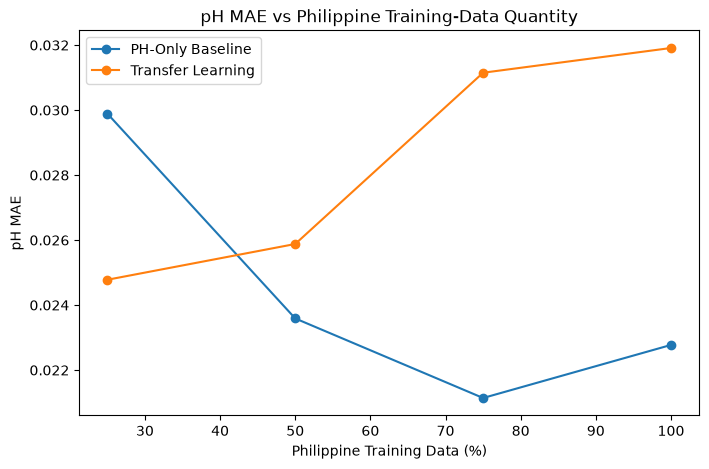

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    compact_results["Training Percentage"],
    compact_results["PH Baseline MAE"],
    marker="o",
    label="PH-Only Baseline"
)

plt.plot(
    compact_results["Training Percentage"],
    compact_results["PH Transfer MAE"],
    marker="o",
    label="Transfer Learning"
)

plt.xlabel("Philippine Training Data (%)")
plt.ylabel("pH MAE")
plt.title("pH MAE vs Philippine Training-Data Quantity")

plt.legend()
plt.show()

## 18. Plot Temperature MAE by Local Training-Data Quantity

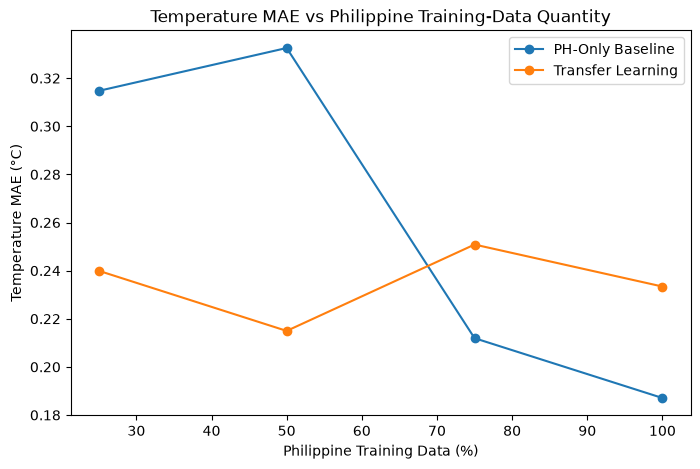

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    compact_results["Training Percentage"],
    compact_results["Temp Baseline MAE"],
    marker="o",
    label="PH-Only Baseline"
)

plt.plot(
    compact_results["Training Percentage"],
    compact_results["Temp Transfer MAE"],
    marker="o",
    label="Transfer Learning"
)

plt.xlabel("Philippine Training Data (%)")
plt.ylabel("Temperature MAE (°C)")
plt.title("Temperature MAE vs Philippine Training-Data Quantity")

plt.legend()
plt.show()

## 19. Local-Data-Quantity Experiment Interpretation

The local-data-quantity experiment evaluated Philippine-only and transfer-learning LSTMs using 25%, 50%, 75%, and 100% of the available Philippine training partition.

At 25% of the local training data, corresponding to 50 hourly observations and 44 generated training sequences, transfer learning outperformed the Philippine-only baseline for both forecasting variables.

For water pH, transfer learning reduced MAE from 0.0299 to 0.0248 and increased R² from 0.7062 to 0.8263.

For water temperature, transfer learning reduced MAE from 0.3147 °C to 0.2399 °C and increased R² from 0.9591 to 0.9644.

At 50% of the Philippine training data, transfer learning continued to improve water-temperature forecasting, while the pH results were mixed. The Philippine-only model achieved a slightly lower pH MAE, while transfer learning produced a slightly higher pH R².

At 75% and 100% of the Philippine training data, the Philippine-only baseline achieved better performance than transfer learning for both variables.

These results indicate that the benefit of transfer learning was strongest under the most data-scarce condition. As the quantity of Philippine training data increased, direct training on the target-domain observations became increasingly competitive and eventually outperformed the transferred model.

## 20. Acceptable-Performance Criterion

For the local-data-quantity experiment, acceptable forecasting performance is operationally defined as achieving an R² value of at least 0.80 for both water pH and water temperature on the fixed Philippine test set.

This threshold is used as a study-specific modeling criterion for determining the minimum quantity of Philippine training data that produces satisfactory predictive performance.

The criterion is not intended to represent a universal aquaculture-management threshold. Rather, it provides a consistent quantitative rule for comparing model performance across reduced local-data conditions.

In [20]:
ACCEPTABLE_R2 = 0.80

acceptability_results = pd.DataFrame({
    "Training Percentage":
        local_data_results["Training Percentage"],

    "Training Rows":
        local_data_results["Training Rows"],

    "PH-Only pH Acceptable":
        local_data_results["PH Baseline R2"]
        >= ACCEPTABLE_R2,

    "PH-Only Temp Acceptable":
        local_data_results["Temp Baseline R2"]
        >= ACCEPTABLE_R2,

    "Transfer pH Acceptable":
        local_data_results["PH Transfer R2"]
        >= ACCEPTABLE_R2,

    "Transfer Temp Acceptable":
        local_data_results["Temp Transfer R2"]
        >= ACCEPTABLE_R2
})

acceptability_results["PH-Only Overall Acceptable"] = (
    acceptability_results[
        "PH-Only pH Acceptable"
    ]
    &
    acceptability_results[
        "PH-Only Temp Acceptable"
    ]
)

acceptability_results["Transfer Overall Acceptable"] = (
    acceptability_results[
        "Transfer pH Acceptable"
    ]
    &
    acceptability_results[
        "Transfer Temp Acceptable"
    ]
)

acceptability_results

,Training Percentage,Training Rows,PH-Only pH Acceptable,PH-Only Temp Acceptable,Transfer pH Acceptable,Transfer Temp Acceptable,PH-Only Overall Acceptable,Transfer Overall Acceptable
0,25,50,False,True,True,True,False,True
1,50,100,True,True,True,True,True,True
2,75,150,True,True,False,True,True,False
3,100,201,True,True,False,True,True,False


In [21]:
acceptable_ph_only = acceptability_results[
    acceptability_results[
        "PH-Only Overall Acceptable"
    ]
]

acceptable_transfer = acceptability_results[
    acceptability_results[
        "Transfer Overall Acceptable"
    ]
]

if len(acceptable_ph_only) > 0:
    min_ph_only = acceptable_ph_only.iloc[0]

    print("Minimum acceptable PH-only data:")
    print(
        int(
            min_ph_only[
                "Training Percentage"
            ]
        ),
        "%"
    )
    print(
        "Rows:",
        int(
            min_ph_only[
                "Training Rows"
            ]
        )
    )
else:
    print(
        "PH-only model did not meet the criterion."
    )


print()


if len(acceptable_transfer) > 0:
    min_transfer = acceptable_transfer.iloc[0]

    print("Minimum acceptable transfer-learning data:")
    print(
        int(
            min_transfer[
                "Training Percentage"
            ]
        ),
        "%"
    )
    print(
        "Rows:",
        int(
            min_transfer[
                "Training Rows"
            ]
        )
    )
else:
    print(
        "Transfer model did not meet the criterion."
    )

Minimum acceptable PH-only data:
50 %
Rows: 100

Minimum acceptable transfer-learning data:
25 %
Rows: 50


## 23. Minimum Local-Data Result

Using the operational requirement that both forecasting targets achieve R² ≥ 0.80, the transfer-learning model achieved acceptable performance using only 25% of the available Philippine training partition.

This condition contained 50 hourly training observations and generated 44 six-hour training sequences.

In comparison, the Philippine-only baseline did not satisfy the criterion at 25% because its pH R² was 0.7062. The Philippine-only baseline first satisfied the criterion at 50% of the Philippine training partition, corresponding to 100 hourly observations and 94 training sequences.

Under this criterion, transfer learning therefore reduced the minimum observed local-data requirement from 100 hourly observations to 50 hourly observations.

However, transfer learning did not consistently outperform the Philippine-only approach as additional local observations became available. At 75% and 100% training-data quantities, the Philippine-only model produced stronger overall forecasting performance.

These findings support the use of transfer learning primarily as a data-scarcity strategy rather than as a universally superior forecasting approach.

In [22]:
local_data_results.to_csv(
    "../results/local_data_quantity_experiment.csv",
    index=False
)

compact_results.to_csv(
    "../results/local_data_compact_results.csv",
    index=False
)

advantage_results.to_csv(
    "../results/local_data_transfer_advantage.csv",
    index=False
)

acceptability_results.to_csv(
    "../results/local_data_acceptability.csv",
    index=False
)

print("Local-data experiment results saved.")

Local-data experiment results saved.


In [23]:
performance_criterion = pd.DataFrame({
    "Criterion": [
        "Minimum R² for pH",
        "Minimum R² for water temperature",
        "Required targets meeting criterion",
        "Minimum PH-only training percentage",
        "Minimum transfer training percentage",
        "Minimum PH-only training rows",
        "Minimum transfer training rows"
    ],

    "Value": [
        0.80,
        0.80,
        "Both",
        50,
        25,
        100,
        50
    ]
})

performance_criterion

,Criterion,Value
0,Minimum R² for pH,0.8
1,Minimum R² for water temperature,0.8
2,Required targets meeting criterion,Both
3,Minimum PH-only training percentage,50
4,Minimum transfer training percentage,25
5,Minimum PH-only training rows,100
6,Minimum transfer training rows,50


In [24]:
performance_criterion.to_csv(
    "../results/acceptable_performance_criterion.csv",
    index=False
)

print(
    "Acceptable-performance criterion saved."
)

Acceptable-performance criterion saved.


## 26. Local-Data Experiment Completion Summary

The local-data-quantity experiment has been completed using 25%, 50%, 75%, and 100% of the available Philippine training partition.

Transfer learning demonstrated its clearest advantage under the smallest local-data condition.

At 25% local training data:

- Philippine training observations: 50
- Training sequences: 44
- Transfer pH MAE: 0.0248
- PH-only pH MAE: 0.0299
- Transfer pH R²: 0.8263
- PH-only pH R²: 0.7062
- Transfer temperature MAE: 0.2399 °C
- PH-only temperature MAE: 0.3147 °C
- Transfer temperature R²: 0.9644
- PH-only temperature R²: 0.9591

Using the study-specific acceptable-performance requirement of R² ≥ 0.80 for both targets, transfer learning satisfied the criterion using 25% of the Philippine training partition, while the Philippine-only model first satisfied the criterion using 50%.

This corresponds to an observed minimum of 50 hourly Philippine training observations for transfer learning compared with 100 hourly observations for the Philippine-only baseline.

As more Philippine data became available, the advantage of transfer learning diminished. At 75% and 100% training-data quantities, direct Philippine-only training achieved stronger overall forecasting performance.

The findings therefore suggest that transfer learning is most beneficial in this study when the target-domain dataset is highly limited.

## 27. Overall Experimental Completion

The complete PondPredict model-development experiment now includes:

1. Source-domain LSTM development and hyperparameter tuning
2. Philippine-only LSTM baseline
3. Source-to-Philippine LSTM transfer learning
4. Paired statistical comparison of Philippine-only and transfer-learning models
5. Local Philippine training-data quantity experiments
6. Operational acceptable-performance criterion
7. Minimum local-data analysis

The resulting models and experiment outputs are preserved in the project `models` and `results` directories for documentation and reproducibility.